# EDA & Data Preprocessing
**Dataset:** Runner Automobile in a Market Point of View – Driver  
This notebook loads the raw CSV, inspects its messy structure, performs preprocessing, and exports a clean dataset that the downstream `cleaning.ipynb` will consume.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 250)

## 1. Load the raw CSV (no header) and inspect

In [2]:
raw = pd.read_csv("Runner Autombile in a Market Point of View - Driver.csv", header=None)
print("Raw shape:", raw.shape)
raw.head(8)

Raw shape: (221, 15)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Price,25.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Number of Shares,"113,540,000",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2018A,2019A,2020A,2021A,2022A,2023A,2024A,2025P,2026P,2027P,2028P,2029P,2030P,NaN
3,Revenue,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Sales (Runner Automobiles PLC),"4,201,493,583","4,324,566,612",3911444446,3790299014,3427415715,"2,877,438,472","4,687,258,415",5734258345,7095336498,8850680103,11105210383,13991316400,17690017747,NaN
5,Credit business income,NaN,NaN,NaN,1041583414,1029733814,"555,460,852","1,011,444,545",1112589000,1223847899,1346232689,1480855958,1628941554,1140259088,NaN
6,YoY Growth of Credit business income,NaN,NaN,NaN,-1.14%,-46.06%,82.09%,10.00%,1.1,1.1,1.1,1.1,1.1,0.7,NaN
7,Sales (Runner Motors Limited),"5,759,522,946.00","6,325,884,240.00","6,070,399,589.00","6,403,666,639.00","6,649,355,866.00","4,103,383,279.00","3,975,774,641.00","4,291,053,468.42","4,685,365,381.91","5,151,905,816.83","5,673,566,850.92","6,280,212,131.79","6,961,932,555.06",NaN


**Observations on the raw file**

- Row 0 contains the share price (`25.8`) and row 1 contains the number of shares (`113,540,000`).
- Row 2 holds the year column headers `2018A … 2030P` (A = Actual, P = Projected).
- Column 0 holds line-item names; columns 1–13 hold yearly values; column 14 is entirely empty.
- Several rows are *section headers* (e.g. `Revenue`, `Cost of sales`) — the line item is filled but every year cell is blank.
- Numeric cells use commas, percent signs, parentheses for negatives, and Excel errors (`#REF!`, `#VALUE!`, `#DIV/0!`).

## 2. Assign proper column names and capture metadata

In [3]:
years = ['2018A','2019A','2020A','2021A','2022A','2023A','2024A',
         '2025P','2026P','2027P','2028P','2029P','2030P']
raw.columns = ['line_item'] + years + ['extra']
raw = raw.drop(columns=['extra'])

price       = raw.iloc[0, 1]
num_shares  = raw.iloc[1, 1]
print(f"Share price : {price}")
print(f"Shares outstanding: {num_shares}")

# Remove metadata + year-header rows
df = raw.iloc[3:].reset_index(drop=True)
print("After dropping metadata rows:", df.shape)

Share price :   25.8 
Shares outstanding: 113,540,000
After dropping metadata rows: (218, 14)


## 3. Drop completely empty rows (separator rows in the spreadsheet)

In [4]:
before = df.shape[0]
df = df.dropna(how='all').reset_index(drop=True)
print(f"Removed {before - df.shape[0]} blank separator rows; shape now {df.shape}")

Removed 11 blank separator rows; shape now (207, 14)


## 4. Convert messy numeric strings to floats

The helper below handles:
- thousand-separator commas → stripped
- percentage strings (`5.87%`) → 0.0587
- accounting negatives in parentheses (`(258,822)`) → −258822
- Excel errors (`#REF!`, `#VALUE!`, `#DIV/0!`) → NaN
- dashes / blanks → NaN

In [5]:
def to_number(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s in ('', '-', 'nan', 'NaN'):
        return np.nan
    if s.startswith('#'):           # #REF!, #VALUE!, #DIV/0!
        return np.nan
    is_pct = s.endswith('%')
    if is_pct:
        s = s[:-1]
    if s.startswith('(') and s.endswith(')'):
        s = '-' + s[1:-1]
    s = s.replace(',', '').replace(' ', '')
    try:
        v = float(s)
        return v / 100.0 if is_pct else v
    except ValueError:
        return np.nan

for c in years:
    df[c] = df[c].apply(to_number)

df.dtypes

line_item        str
2018A        float64
2019A        float64
2020A        float64
2021A        float64
2022A        float64
2023A        float64
2024A        float64
2025P        float64
2026P        float64
2027P        float64
2028P        float64
2029P        float64
2030P        float64
dtype: object

## 5. Extract section headers into their own column

A row is a *section header* when the line-item label is present but every year cell is NaN. We forward-fill it into a new `section` column so each numeric row keeps its category context.

In [6]:
df['line_item'] = df['line_item'].astype(str).str.strip()

all_year_nan = df[years].isna().all(axis=1)
is_section   = all_year_nan & (df['line_item'] != 'nan')

df['section'] = np.where(is_section, df['line_item'], np.nan)
df['section'] = df['section'].ffill()

# Remove the section-header rows themselves and any leftover 'nan' labels
df = df[~is_section].reset_index(drop=True)
df = df[df['line_item'] != 'nan'].reset_index(drop=True)

df = df[['section','line_item'] + years]
print("Cleaned wide-form shape:", df.shape)
print("Sections found:", df['section'].unique())
df.head(10)

Cleaned wide-form shape: (202, 15)
Sections found: <StringArray>
[                           'Revenue', 'Break-up of sales revenue by RAPLC',
   'Break-up of sales revenue by RML',                      'Cost of sales',
                   'Retained Earning']
Length: 5, dtype: str


,section,line_item,2018A,2019A,2020A,2021A,2022A,2023A,2024A,2025P,2026P,2027P,2028P,2029P,2030P
0,Revenue,Sales (Runner Automobiles PLC),4.201494e+09,4.324567e+09,3.911444e+09,3.790299e+09,3.427416e+09,2.877438e+09,4.687258e+09,5.734258e+09,7.095336e+09,8.850680e+09,1.110521e+10,1.399132e+10,1.769002e+10
1,Revenue,Credit business income,NaN,NaN,NaN,1.041583e+09,1.029734e+09,5.554609e+08,1.011445e+09,1.112589e+09,1.223848e+09,1.346233e+09,1.480856e+09,1.628942e+09,1.140259e+09
2,Revenue,YoY Growth of Credit business income,NaN,NaN,NaN,-1.140000e-02,-4.606000e-01,8.209000e-01,1.000000e-01,1.100000e+00,1.100000e+00,1.100000e+00,1.100000e+00,1.100000e+00,7.000000e-01
3,Revenue,Sales (Runner Motors Limited),5.759523e+09,6.325884e+09,6.070400e+09,6.403667e+09,6.649356e+09,4.103383e+09,3.975775e+09,4.291053e+09,4.685365e+09,5.151906e+09,5.673567e+09,6.280212e+09,6.961933e+09
4,Revenue,YoY Sales (Runner Motors Limited),9.830000e-02,-4.040000e-02,5.490000e-02,3.840000e-02,-3.829000e-01,-3.110000e-02,7.930000e-02,9.190000e-02,9.960000e-02,1.013000e-01,1.069000e-01,1.086000e-01,-1.000000e+00
5,Revenue,Value Added Tax,NaN,NaN,NaN,NaN,NaN,9.784863e+08,1.042608e+09,1.094738e+09,1.149475e+09,1.206949e+09,1.267296e+09,1.330661e+09,1.463727e+09
6,Revenue,YoY VAT %,NaN,NaN,NaN,NaN,NaN,6.550000e-02,5.000000e-02,1.050000e+00,1.050000e+00,1.050000e+00,1.050000e+00,1.050000e+00,1.100000e+00
7,Revenue,Total Revenue,9.961017e+09,1.065045e+10,9.981844e+09,1.123555e+10,1.110651e+10,6.557796e+09,8.363583e+09,1.004316e+10,1.185507e+10,1.414187e+10,1.699234e+10,2.056981e+10,2.432848e+10
8,Revenue,Total Revenue Growth,6.920000e-02,-6.280000e-02,1.256000e-01,-1.150000e-02,-4.096000e-01,2.754000e-01,2.008000e-01,1.804000e-01,1.929000e-01,2.016000e-01,2.105000e-01,1.827000e-01,-1.000000e+00
9,Revenue,Population (million),1.663700e+02,1.678900e+02,1.693600e+02,1.708600e+02,1.725400e+02,1.742700e+02,1.754000e+02,1.770000e+02,1.790000e+02,1.810000e+02,1.830000e+02,1.850000e+02,1.880000e+02


## 6. Quick checks — missing values per year and duplicates

In [7]:
print("Non-null counts per year:")
print(df[years].notna().sum())
print()
print("Duplicate line_items:", df['line_item'].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

Non-null counts per year:
2018A    118
2019A    126
2020A    128
2021A    136
2022A    137
2023A    195
2024A    194
2025P    173
2026P    173
2027P    173
2028P    173
2029P    173
2030P    169
dtype: int64

Duplicate line_items: 56
Fully duplicated rows: 0


Some line-item labels repeat (e.g. `as a % of Sales`, `YoY Growth Rate`) because they sit under different parent items. They are **not true duplicates** — the `section` column disambiguates them.

## 7. Build a tidy long-form version for easier analysis

In [8]:
long_df = df.melt(
    id_vars=['section','line_item'],
    value_vars=years,
    var_name='period',
    value_name='value'
)
long_df['year']        = long_df['period'].str[:4].astype(int)
long_df['period_type'] = long_df['period'].str[-1].map({'A':'Actual','P':'Projected'})
long_df = long_df[['section','line_item','period','year','period_type','value']]
print("Long-form shape:", long_df.shape)
long_df.head()

Long-form shape: (2626, 6)


,section,line_item,period,year,period_type,value
0,Revenue,Sales (Runner Automobiles PLC),2018A,2018,Actual,4.201494e+09
1,Revenue,Credit business income,2018A,2018,Actual,NaN
2,Revenue,YoY Growth of Credit business income,2018A,2018,Actual,NaN
3,Revenue,Sales (Runner Motors Limited),2018A,2018,Actual,5.759523e+09
4,Revenue,YoY Sales (Runner Motors Limited),2018A,2018,Actual,9.830000e-02


## 8. Save the cleaned datasets

In [9]:
df.to_csv("clean_runner_automobile.csv", index=False)
long_df.to_csv("clean_runner_automobile_long.csv", index=False)
print("Saved: clean_runner_automobile.csv (wide form)")
print("Saved: clean_runner_automobile_long.csv (long form)")

Saved: clean_runner_automobile.csv (wide form)
Saved: clean_runner_automobile_long.csv (long form)


## 9. Quick visual sanity check — total revenue trajectory

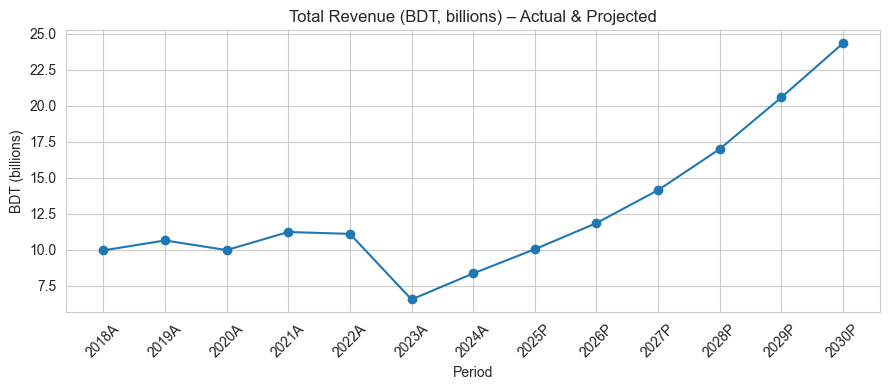

In [10]:
rev = df[df['line_item']=='Total Revenue'][years].T
rev.columns = ['Total Revenue']
rev.index.name = 'Period'

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(rev.index, rev['Total Revenue']/1e9, marker='o')
ax.set_title("Total Revenue (BDT, billions) – Actual & Projected")
ax.set_xlabel("Period")
ax.set_ylabel("BDT (billions)")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Preprocessing complete.** The downstream `cleaning.ipynb` reads `clean_runner_automobile.csv` (and the long version when convenient) and carries out the assignment tasks: dataset description, column typing, EDA, visualisations, and insights.